# Results report – Tree Growth project

This notebook explains the results of the project. It does not run the algorithms: it only reads the tables and figures that `main.py` saves in `results/`.

In [1]:
import os
import pandas as pd
from IPython.display import Image, display

ROOT = os.path.abspath('..')
TABLES = os.path.join(ROOT, 'results', 'tables')
FIGURES = os.path.join(ROOT, 'results', 'figures')
table = lambda name, **kw: pd.read_csv(os.path.join(TABLES, name), **kw)
figure = lambda name: display(Image(os.path.join(FIGURES, name)))

## 1. Extracted features and their meaning

Each sprout is described by seven features computed from its internode lengths:

- **max_length** gives the longest internode of the sprout, that is, how far the sprout managed to grow at its best point. The median is 0.50 cm in the four treated groups, compared to 1.30 cm in the control group and 3.95 cm in methanol_control: the regulators prevented the sprouts from producing long internodes.
- **mean_length** is the typical internode of the sprout, which shows how the sprout grew in general. Its median goes from 0.35 to 0.50 cm in the treated groups, compared to 0.83 cm and 2.03 cm in the controls, so the regulators shortened all the internodes, not only the longest one.
- **std_length** tells how unequal the internodes are, in centimeters. Since it is measured in cm, it also depends on the size of the sprout: a larger sprout has a larger standard deviation even if its internodes are equally uneven. For this reason it was almost perfectly correlated with the size features (r between 0.97 and 1.00).
- **cv_length** is the normalized version of std_length (std / mean). It tells whether the internodes are equal or different compared to their average size, independently of how much the sprout grew. For example, a sprout with internodes of 1, 2 and 3 cm and another one with 10, 20 and 30 cm have the same shape and the same cv_length (0.41), although the second one is ten times larger. Its median is 0 in the four treated groups, which means that more than half of the treated sprouts have all their internodes equal, or only one internode: they are tiny and uniform sprouts. In the controls the median is 0.48 and 0.61. cv_length has the highest FDR of all features (0.338) and a lower correlation with the size features (r between 0.62 and 0.73), so it adds new information.
- **energy** and **rms** square the internode lengths, so they summarize the size of the sprout giving more weight to the long internodes: one long internode increases them a lot.
- **low_freq_ratio** gives the shape of the sprout from its FFT: close to 1 means a smooth arch and close to 0 a zigzag. Its median barely changes between treatments (0.86 to 0.93), so the regulators change the size of the sprouts much more than their shape. It cannot be computed for 1,774 sprouts, which have less than four internodes or all their internodes equal.

These features matter for the research question because they separate three effects of the growth regulators: how much the sprouts grow (max_length, mean_length, energy, rms), how uneven their internodes are (std_length, cv_length) and what shape they have (low_freq_ratio).

## 2. Data overview

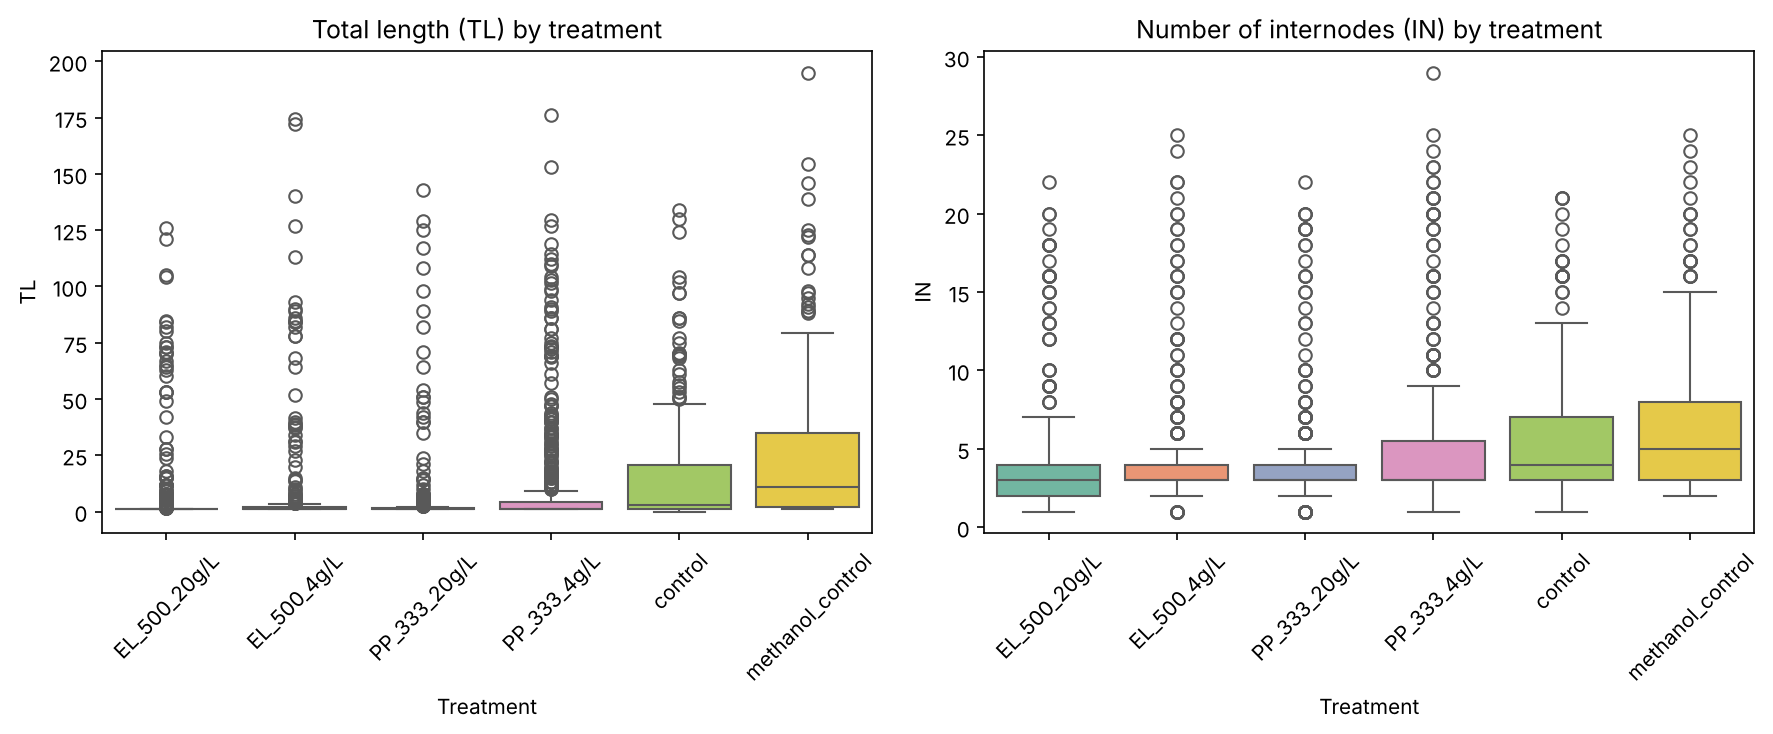

In [2]:
figure('boxplot_tl_in.png')

The boxplots of the total sprout length (TL) and the number of internodes (IN) show two key findings:

1. **Treated groups:** they show a marked concentration of short sprouts, with a median around 1 cm, and numerous outliers above the box. Because almost all sprouts in these groups are close to 1 cm, the box is extremely small, so any slightly longer sprout is flagged as an outlier. This pattern reflects the highly skewed shape of the distribution rather than data errors.
2. **Control groups:** they show considerably longer sprouts and a higher variance.

The outliers were kept in the analysis, because they are biologically plausible observations. Removing them would make the treated groups look artificially uniform and would change the comparison between treatments, which is precisely the effect this analysis wants to measure. Because the distributions are so skewed, the median represents the typical sprout better than the mean: for example, in PP_333_20g/L the mean of TL is 3.7 cm while the median is 1.0 cm.

## 3. Distribution of the features

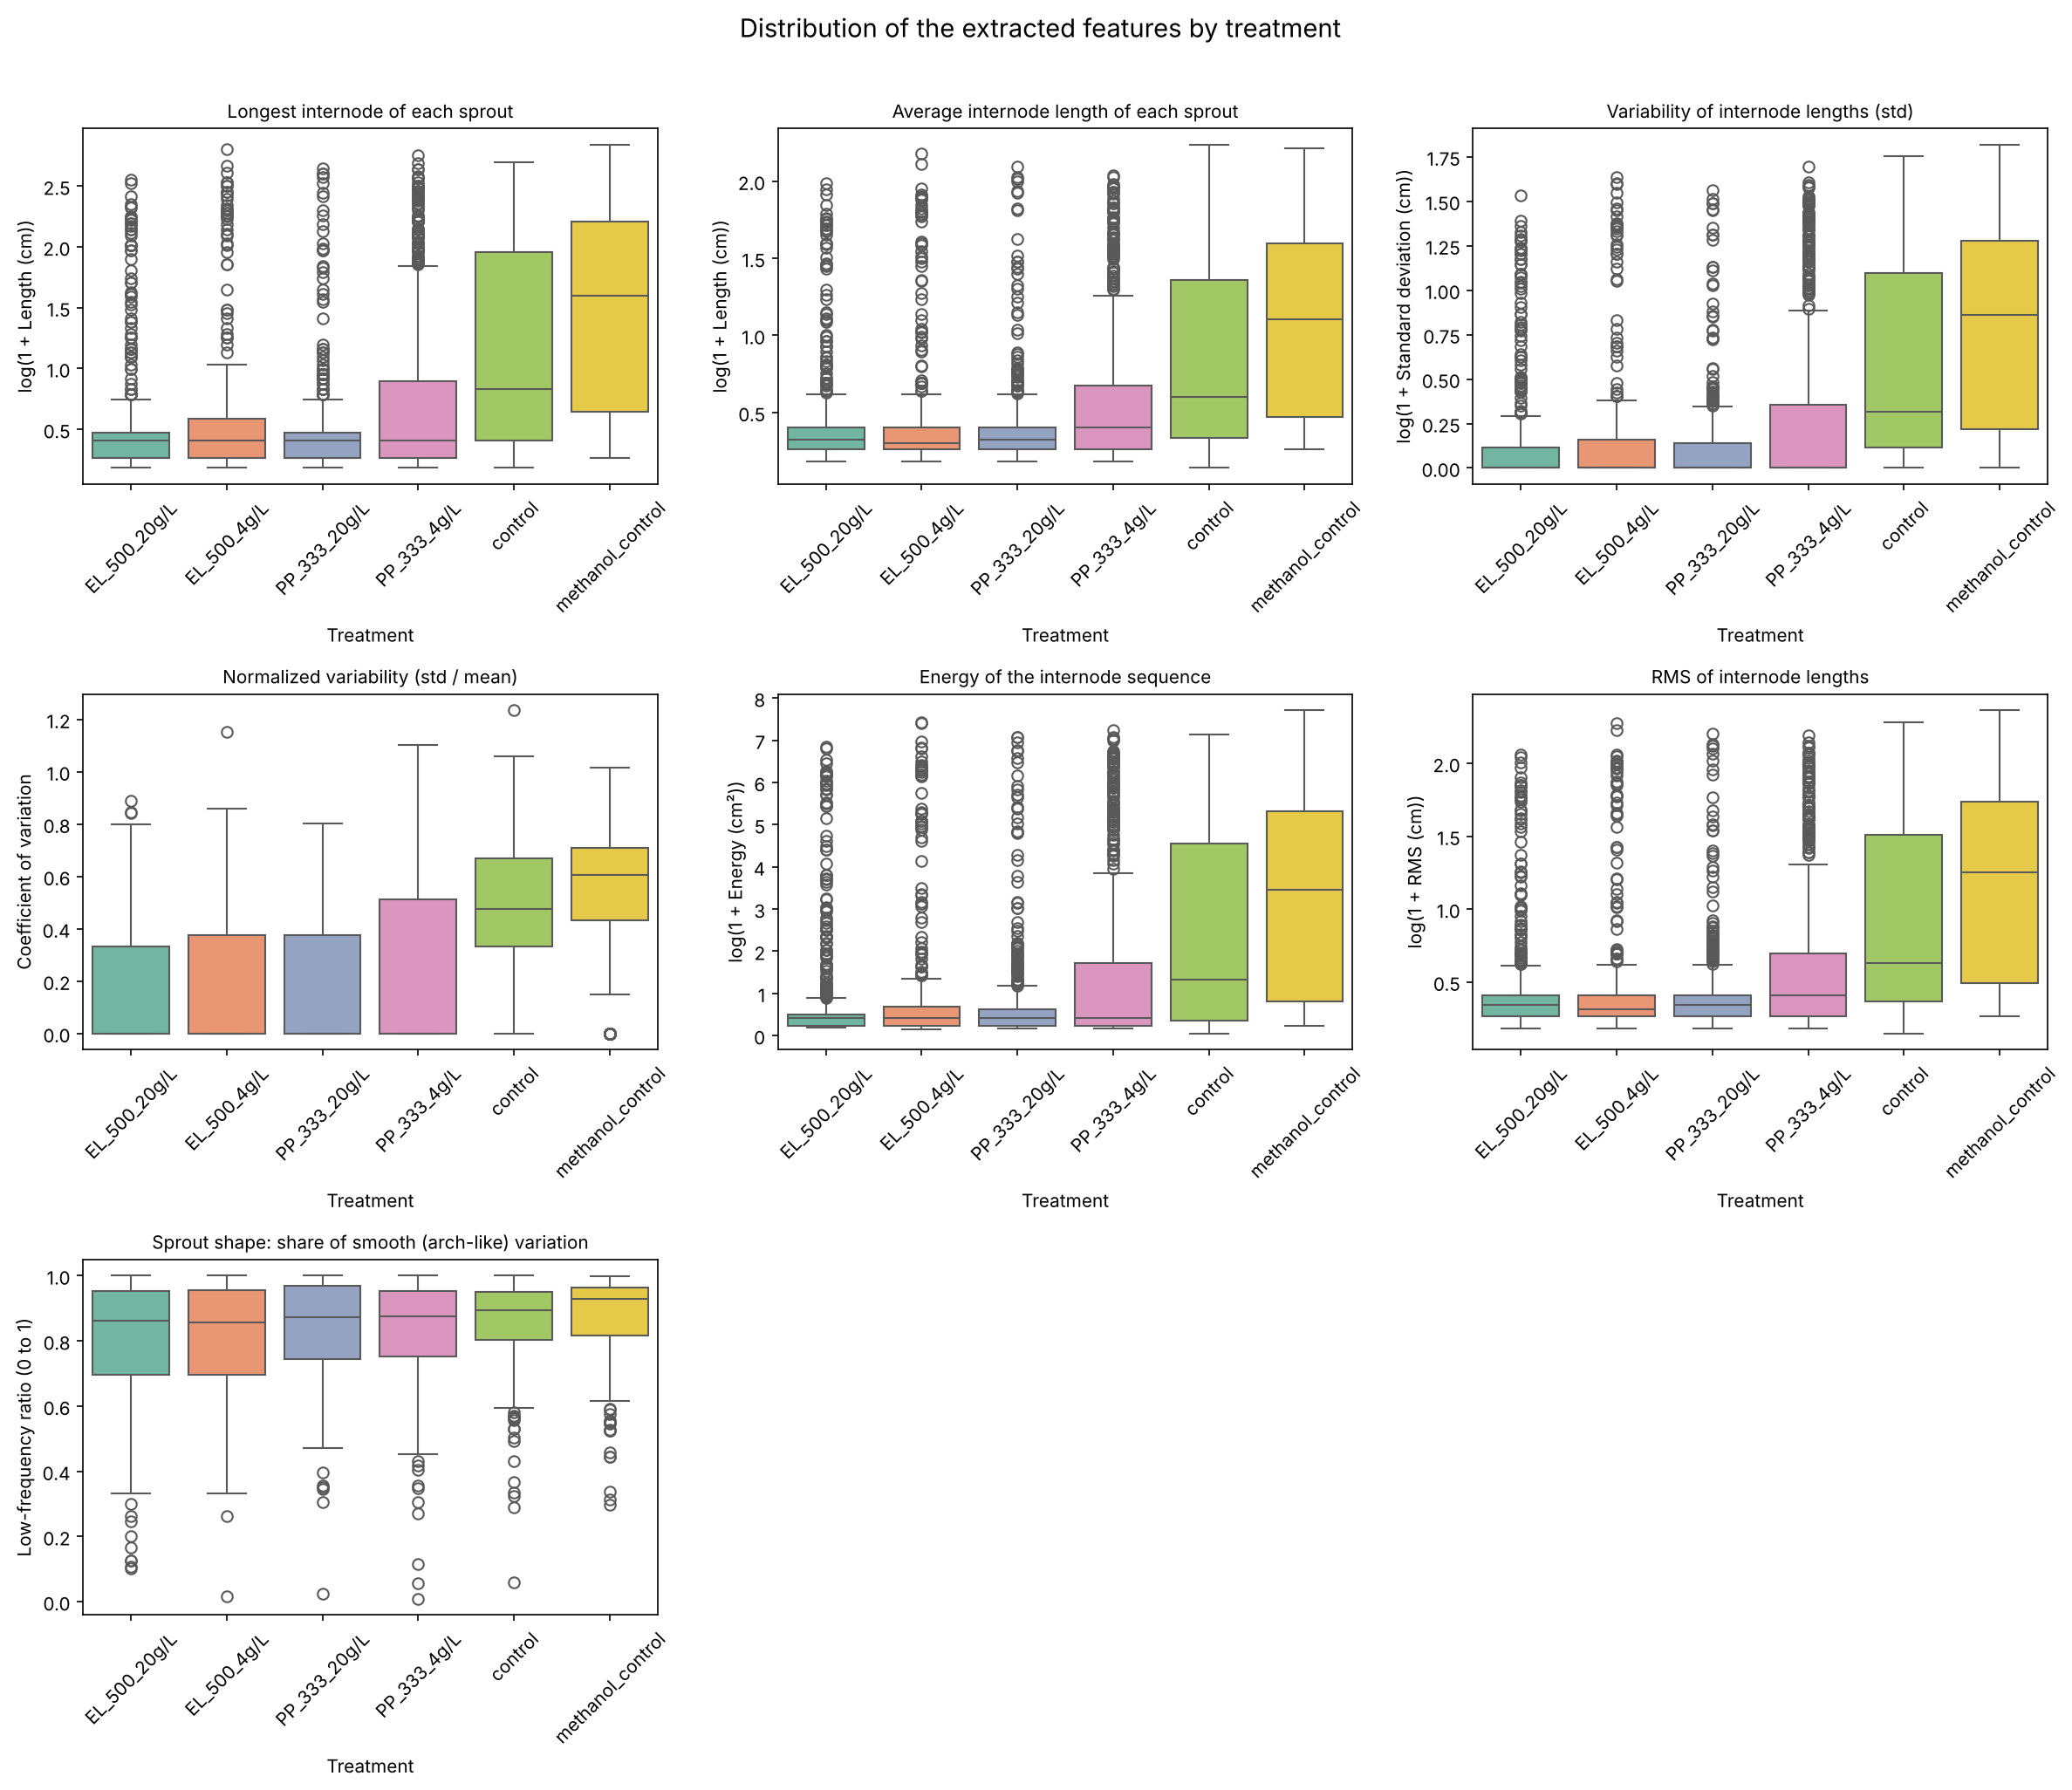

In [3]:
figure('boxplot_features.png')

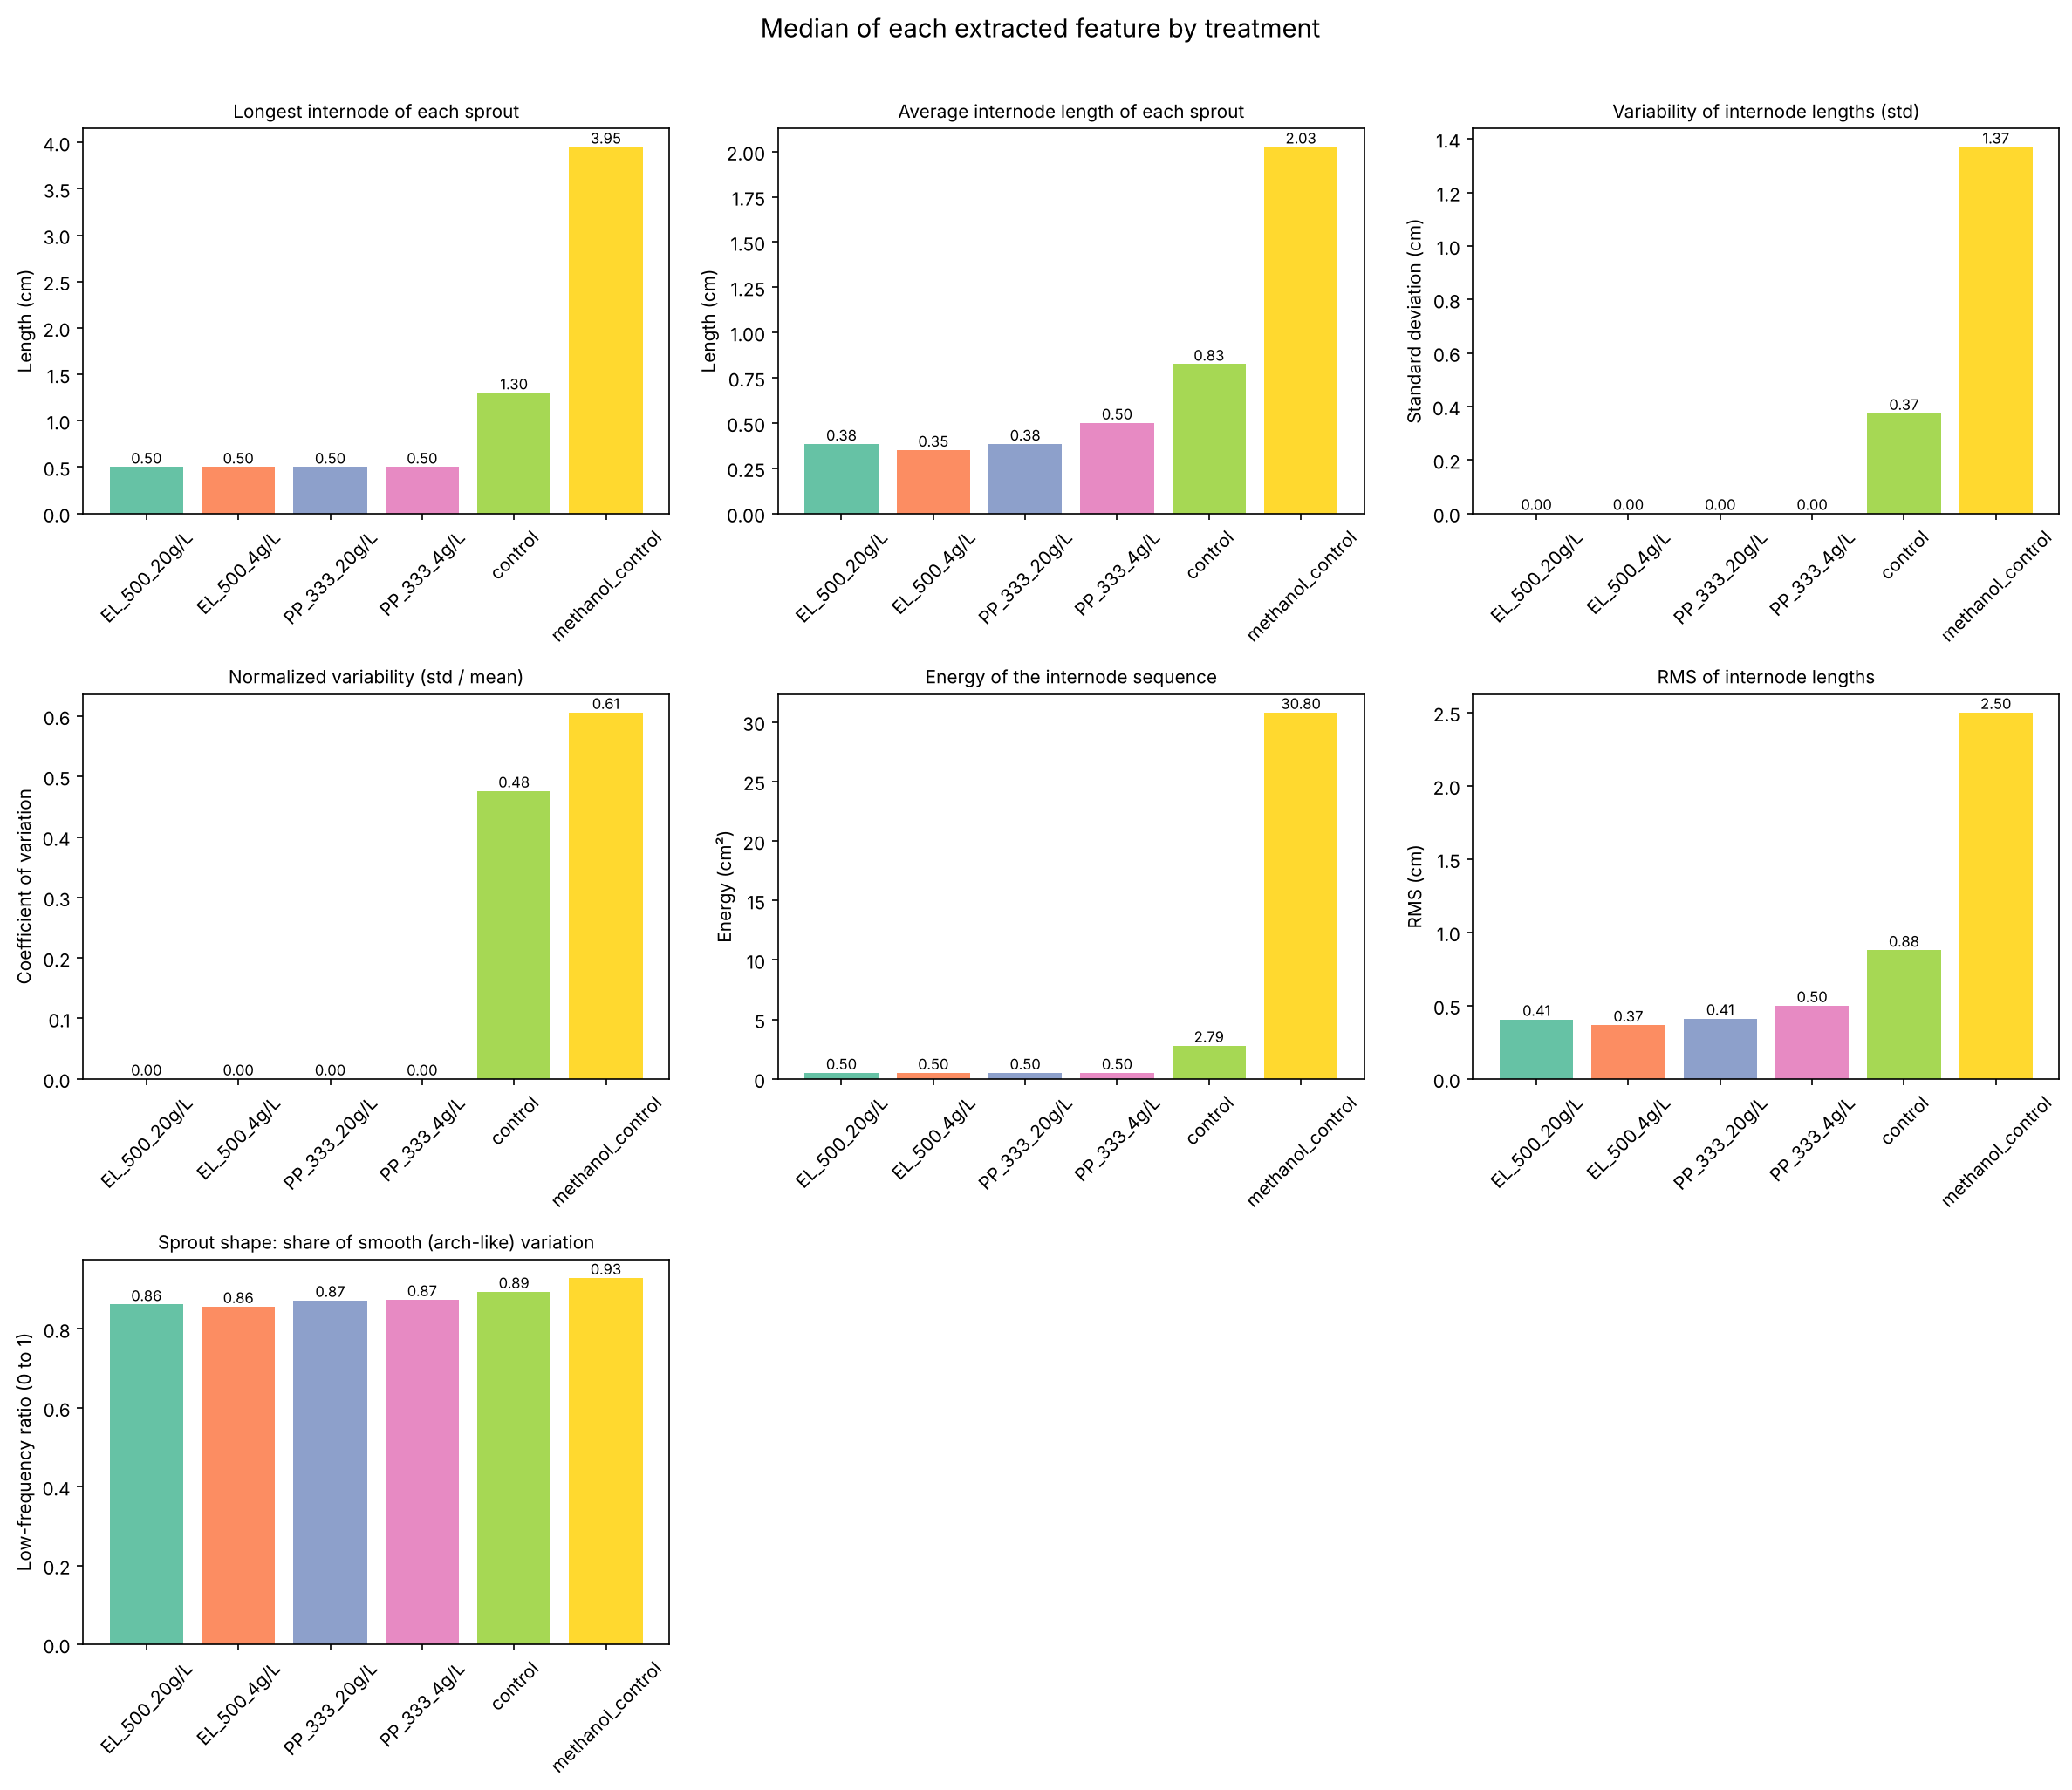

In [4]:
figure('median_barplot.png')

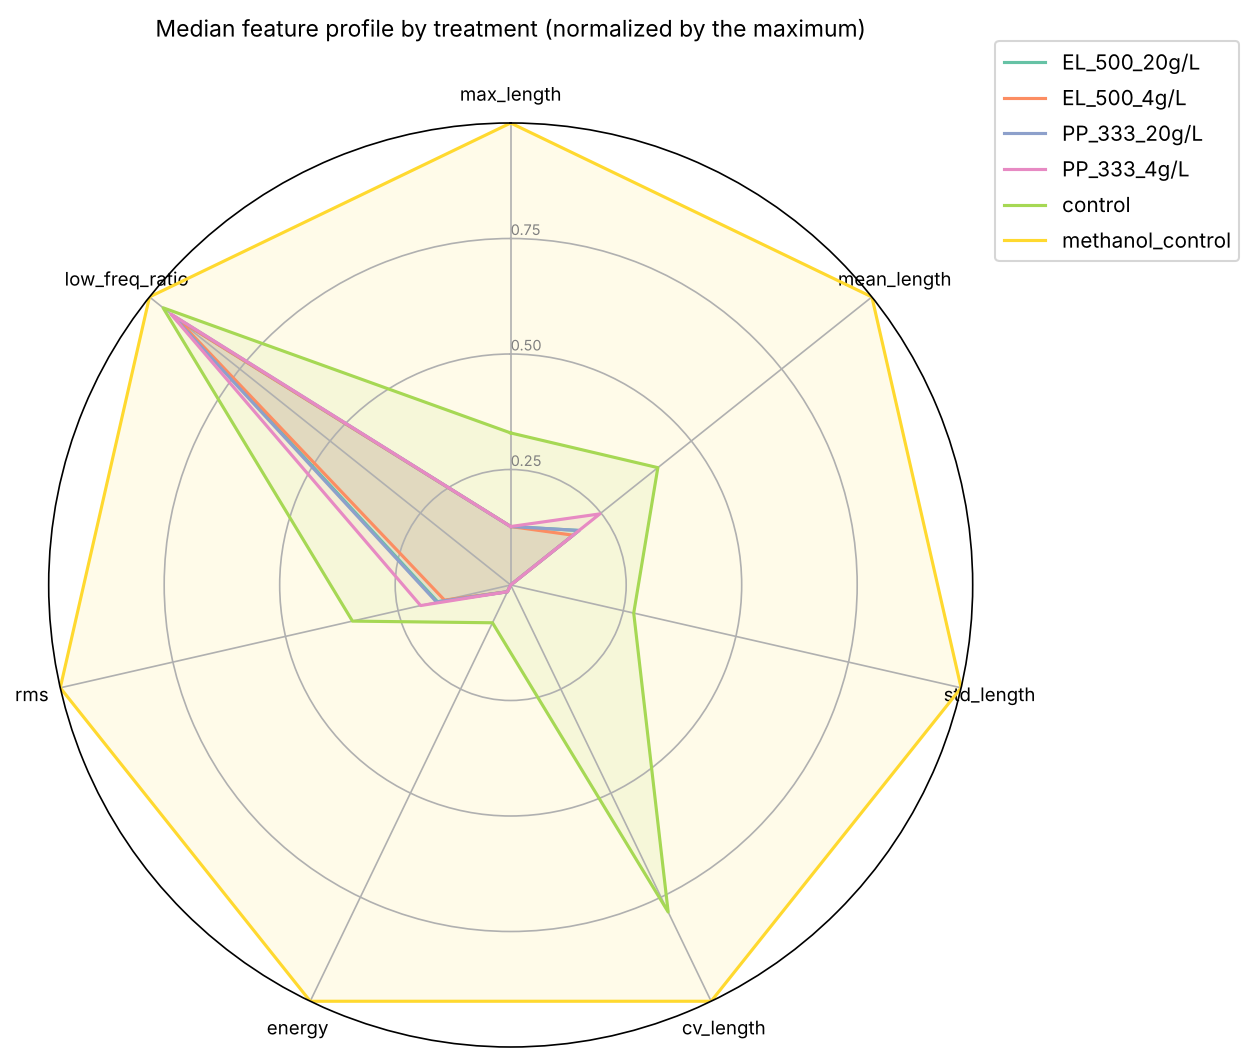

In [5]:
figure('radar_plot.png')

The violin and scatter plots used in Lab 2 were replaced, because they do not work well with this dataset: most treated sprouts are concentrated near zero, so the violins were flattened and the scatter plot was saturated. Boxplots on a log(1 + x) scale, median bar plots and a radar plot are used instead.

The plots show a clear difference in sprout size between treated and control groups. In the boxplots and the bar charts, the four treated groups are concentrated near the bottom of the scale and have almost the same medians, for example 0.50 cm for maximum length, while the control group reaches 1.30 cm and methanol_control 3.95 cm. The median of std_length and cv_length is 0 in all treated groups, which means that more than half of these sprouts have one internode or all their internodes with the same length. In the controls, cv_length has medians of 0.48 and 0.61: their internodes are clearly uneven, as in a sprout that grew with an arch shape.

The shape of the sprouts changes very little. The low-frequency ratio has medians between 0.86 and 0.93 in all groups, and in the radar chart all polygons are close to the outer edge on that axis, while the treated groups form small, overlapping polygons near the center. In summary, the regulators reduce the size of the sprouts and make their internodes more uniform, but barely change their shape, and the four treatments are very similar to each other.

## 4. Statistical tests

In [6]:
table('kruskal_wallis.csv', index_col=0)

,test,statistic,p_value
feature,,,
max_length,Kruskal-Wallis,587.650136,9.421209e-125
mean_length,Kruskal-Wallis,497.904877,2.261946e-105
std_length,Kruskal-Wallis,737.143819,4.562123e-157
cv_length,Kruskal-Wallis,713.382648,6.274135e-152
energy,Kruskal-Wallis,435.793245,5.694099e-92
rms,Kruskal-Wallis,515.023829,4.561248e-109
low_freq_ratio,Kruskal-Wallis,16.451522,5.666501e-03


In [7]:
table('control_vs_methanol.csv', index_col=0)

,statistic,p_value
feature,,
max_length,32.428122,1.236836e-08
mean_length,37.573986,8.801046e-10
std_length,26.693986,2.383623e-07
cv_length,15.176717,9.790317e-05
energy,35.929384,2.045998e-09
rms,38.434263,5.662939e-10
low_freq_ratio,5.844005,1.563021e-02


The Shapiro-Wilk test showed that none of the seven features follows a normal distribution in all treatment groups, as expected from the skewed distributions seen in the plots. For this reason, the Kruskal-Wallis test was used for all features. The six spatial features show significant differences between treatments, with very large statistics, from 436 to 737, and p-values close to zero. The highest statistics belong to std_length (737) and cv_length (713), so the variability of the internodes is what best distinguishes the treatments.

The low-frequency ratio is also significant (p = 0.006), but its statistic is only 16.5, many times smaller than those of the spatial features. With more than a thousand sprouts, even small differences can be significant, which shows that statistical significance does not always mean a large effect. This agrees with the plots, where the shape of the sprouts changes very little. The Kruskal-Wallis test only shows that at least one treatment is different, not which one; the plots suggest that the main differences are between the control and treated groups.

Methanol is only the solvent for the growth regulators, so the control and methanol_control groups were expected to be the same. However, the six spatial features show significant differences between them, with p-values between 10⁻¹⁰ and 10⁻⁴, and methanol_control has larger sprouts. The low-frequency ratio shows no significant difference at the 0.01 level. A likely explanation is the design of the study: each tree received only one treatment, each group has only nine or ten trees, and the trees are very different from each other (in the control groups, the median mean length per tree goes from 0.43 cm to 4.85 cm). Therefore, the difference between the two controls may depend on which trees ended up in each group more than on the methanol itself.

## 5. Separability

In [8]:
table('fdr.csv', index_col=0)

,FDR
cv_length,0.338064
std_length,0.274816
max_length,0.234851
rms,0.230322
mean_length,0.213200
energy,0.064813
low_freq_ratio,0.023032


In [9]:
table('auc_one_vs_rest.csv', index_col=0).round(3)

,EL_500_20g/L,EL_500_4g/L,PP_333_20g/L,PP_333_4g/L,control,methanol_control
max_length,0.632,0.601,0.612,0.502,0.707,0.801
mean_length,0.615,0.591,0.615,0.515,0.668,0.797
std_length,0.637,0.602,0.620,0.522,0.757,0.796
cv_length,0.633,0.601,0.617,0.524,0.758,0.785
energy,0.613,0.576,0.603,0.509,0.644,0.793
rms,0.617,0.601,0.613,0.517,0.670,0.804
low_freq_ratio,0.549,0.546,0.505,0.529,0.510,0.581


In [10]:
table('auc_control_vs_treated.csv', index_col=0).round(3)

,AUC
std_length,0.816
cv_length,0.811
max_length,0.784
rms,0.761
mean_length,0.755
energy,0.737
low_freq_ratio,0.558


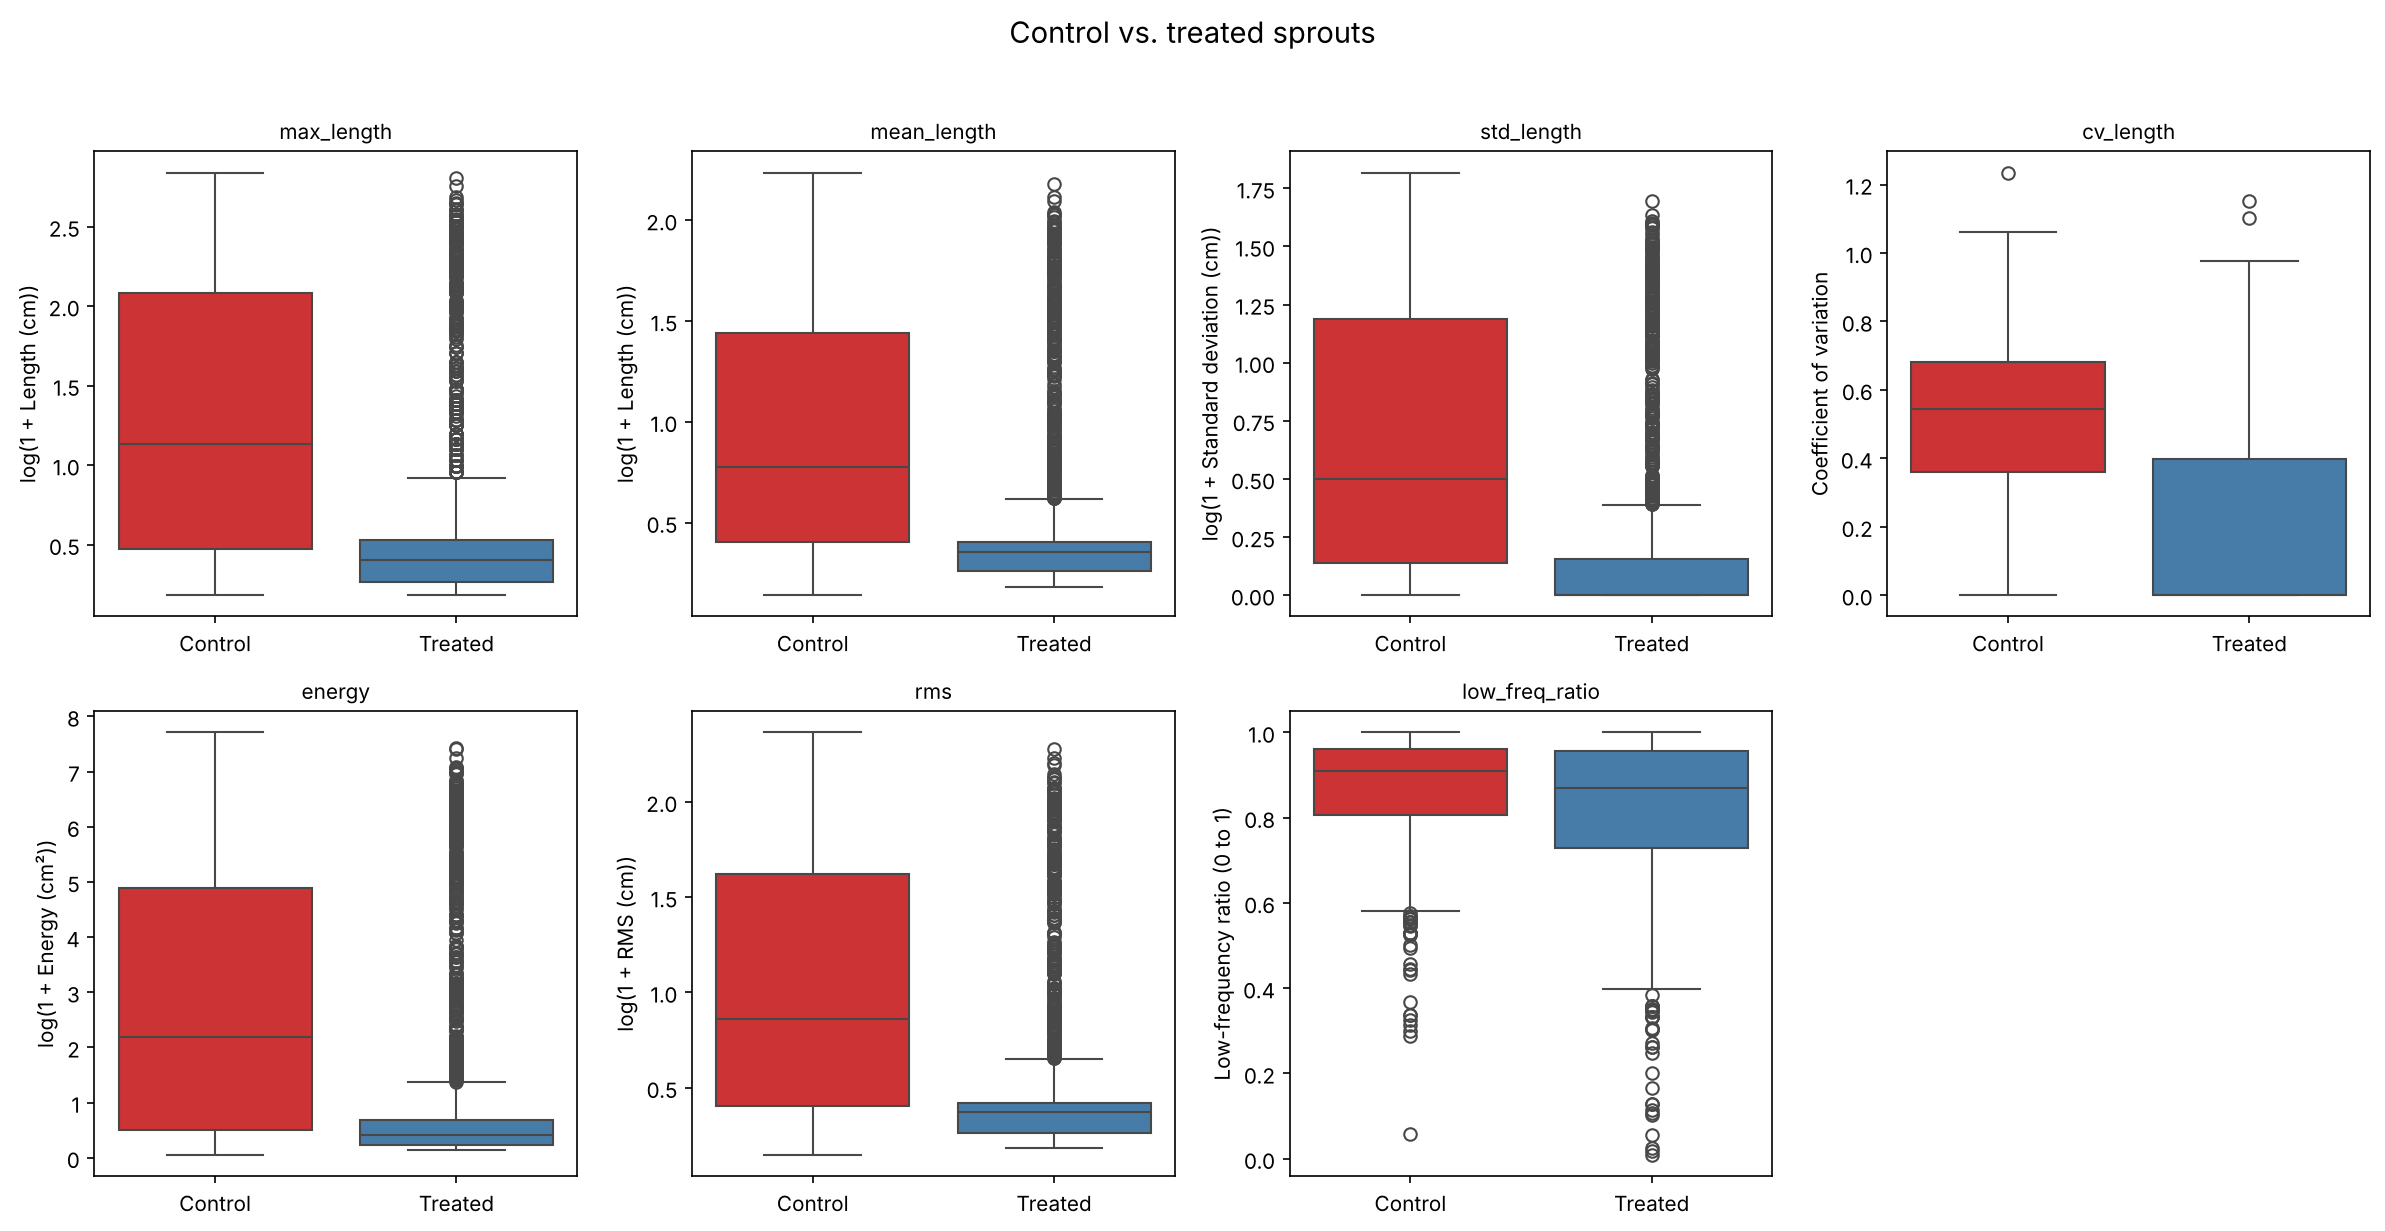

In [11]:
figure('boxplot_control_vs_treated.png')

In [12]:
table('threshold_rule.csv').round(3)

,threshold,TP,TN,FP,FN,accuracy,precision,recall,F1
0,0.30,420,1750,357,268,0.776,0.541,0.610,0.573
1,0.50,368,1848,259,320,0.793,0.587,0.535,0.560
2,0.75,333,1890,217,355,0.795,0.605,0.484,0.538
3,1.00,304,1916,191,384,0.794,0.614,0.442,0.514


**Fisher Discriminant Ratio:** cv_length has the highest FDR (0.338), followed by std_length (0.275), max_length (0.235), rms (0.230) and mean_length (0.213), while energy (0.065) and low_freq_ratio (0.023) are the lowest. The ranking agrees with Kruskal-Wallis. All values are low: the dispersion between treatments is much smaller than the dispersion within each treatment, so the groups overlap a lot from sprout to sprout. The normalization of std_length improved the separation, because cv_length measures the uniformity of the internodes without mixing it with the size of the sprout.

**AUC:** the separation between control and treated sprouts is moderate, with an AUC of 0.82 for std_length and 0.81 for cv_length. The ability of the features to distinguish each specific treatment from the rest is weak, with AUC values between 0.50 and 0.64 for the treated groups, which reflects a high overlap between the different compounds and doses. methanol_control is the easiest group to distinguish (AUC around 0.80), and low_freq_ratio barely separates any group (0.51 to 0.58).

**Classification rule based on std_length:** accuracy is misleading in this case. Although the rule reaches values from 0.78 to 0.80, a baseline that classifies all sprouts as treated, the majority class, already reaches 0.754. Taking control as the positive class, increasing the threshold raises the precision from 0.54 to 0.61, but the recall drops from 0.61 to 0.44. The best balance is found with a threshold of 0.3, with a maximum F1-score of 0.573. False positives are treated sprouts that did grow, and false negatives are control sprouts with naturally reduced growth.

**Conclusion:** the growth regulators reduce the size of the sprouts and make their internodes more uniform, but barely change the shape of their growth pattern. Control and treated sprouts can be separated moderately, while the four treatments are very similar to each other. These results must be interpreted considering the design of the study: each treatment has only nine or ten trees, the sprouts from the same tree are not independent, and the variability between trees is high.